[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/18_semi_supervised_pu.py)

# Semi-Supervised and Positive-Unlabeled Fitting

Often only some rows have labels: a few confirmed examples, or a handful of annotated classes among mostly raw data. `fit(X, labels=...)` accepts partial labels (`-1` marks an unknown row) on every mixture family via the shared `BaseMixture`, running semi-supervised EM in which labeled rows keep their known component assignment while unlabeled rows are soft-assigned as usual. `PositiveUnlabeledMixture` handles the harder case where *only positives* are ever labeled (positive-unlabeled learning, Elkan & Noto, 2008).

**What you'll learn**

- how much a small labeled fraction (5-20%) helps cluster recovery on ambiguous, overlapping data
- how to run PU learning with a Student-t mixture and read the estimated class prior `class_prior_` and per-row positive probabilities
- how the SCAR assumption (labeled positives are a uniform random subsample of all positives) makes this identifiable

**Prerequisites:** [05 -- Supervised Fitting](05_supervised_gmm.ipynb), [16 -- Student-t Mixtures](16_student_t.ipynb), [17 -- Von Mises-Fisher Mixtures](17_von_mises_fisher.ipynb).
See also the [Semi-Supervised and Positive-Unlabeled Fitting](../user-guide/semi-supervised-pu.md) user guide, which covers the terms (SCAR, mixture proportion estimation, `anchor`).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from tgmm import GaussianMixture, StudentTMixture, PositiveUnlabeledMixture
from tgmm.metrics import ClusteringMetrics
from tgmm.plotting import plot_gmm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f'Using device: {device}')

Using device: cpu


## Part 1: semi-supervised fitting on three overlapping blobs

Three overlapping 2-D blobs where unsupervised EM's cluster <-> class correspondence is
genuinely ambiguous. We compare fits at 5%, 20%, and 100% of rows labeled, against plain
unsupervised EM (0% labeled) on the same data.

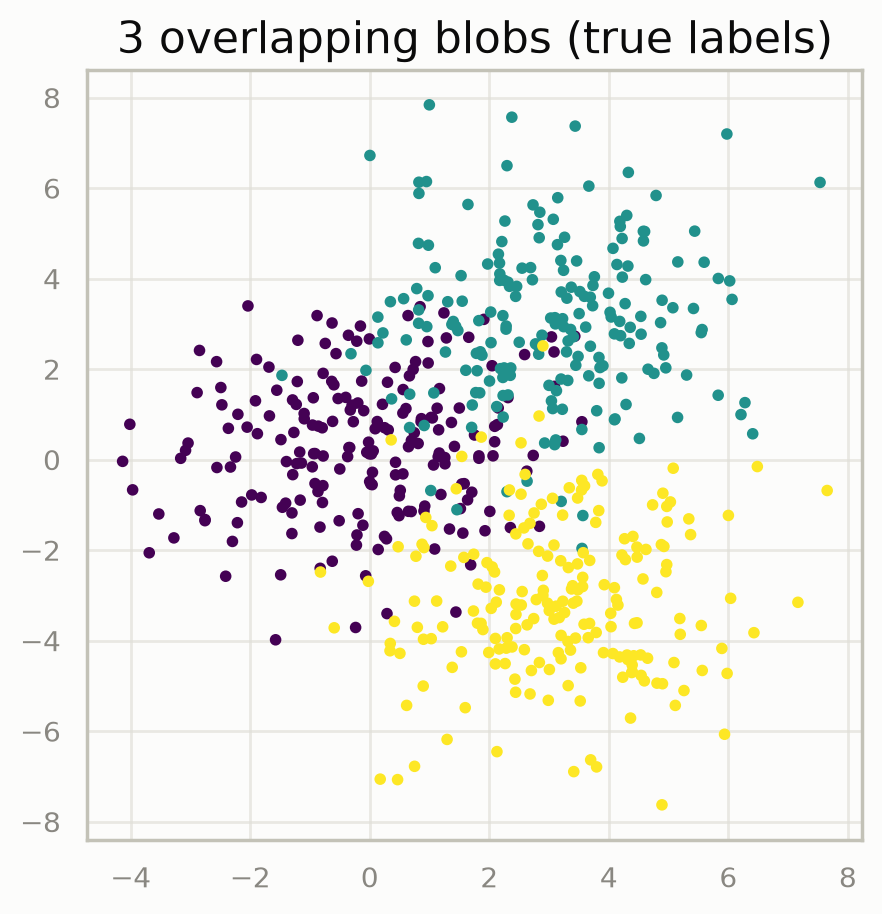

In [ ]:
_gen = torch.Generator().manual_seed(SEED)
n_per = 200
true_centers = torch.tensor([[0.0, 0.0], [3.0, 3.0], [3.0, -3.0]])
X = torch.cat([torch.randn(n_per, 2, generator=_gen) * 1.6 + true_centers[0], torch.randn(n_per, 2, generator=_gen) * 1.6 + true_centers[1], torch.randn(n_per, 2, generator=_gen) * 1.6 + true_centers[2]])
true_labels = torch.cat([torch.full((n_per,), _k) for _k in range(3)])
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=true_labels, cmap='viridis', s=10)
plt.title('3 overlapping blobs (true labels)')
plt.gcf()

In [ ]:
def partial_labels(labels, frac, seed):
    gen = torch.Generator().manual_seed(seed)
    mask = torch.rand(labels.shape[0], generator=gen) < frac
    return (torch.where(mask, labels, torch.full_like(labels, -1)), mask)
label_fracs = [0.0, 0.05, 0.2, 1.0]
# init_means='random' + n_init=1 (rather than the usual kmeans + n_init>1)
# so unsupervised EM's local-optimum quality genuinely depends on luck --
# otherwise a good initialization alone already resolves this data well
# regardless of labels, since ARI is itself invariant to how clusters are
# *numbered* (only labels fix that, which ARI doesn't measure).
aris_by_frac = {frac: [] for frac in label_fracs}
example_models = {}
n_seeds = 4 if FAST else 10
for seed in range(n_seeds):
    for _frac in label_fracs:
        labels = None if _frac == 0.0 else partial_labels(true_labels, _frac, seed=100 + seed)[0]
        _gmm = GaussianMixture(n_components=3, init_means='random', random_state=seed, n_init=1, max_iter=200)
        _gmm.fit(X, labels=labels)
        aris_by_frac[_frac].append(ClusteringMetrics.adjusted_rand_score(true_labels, _gmm.predict(X)))
        if seed == 0:
            example_models[_frac] = _gmm
for _frac in label_fracs:
    vals = aris_by_frac[_frac]
    print(f'{int(_frac * 100):3d}% labeled: mean ARI = {sum(vals) / len(vals):.3f} (over {n_seeds} random-init seeds)')

  0% labeled: mean ARI = 0.375 (over 4 random-init seeds)
  5% labeled: mean ARI = 0.558 (over 4 random-init seeds)
 20% labeled: mean ARI = 0.695 (over 4 random-init seeds)
100% labeled: mean ARI = 0.704 (over 4 random-init seeds)


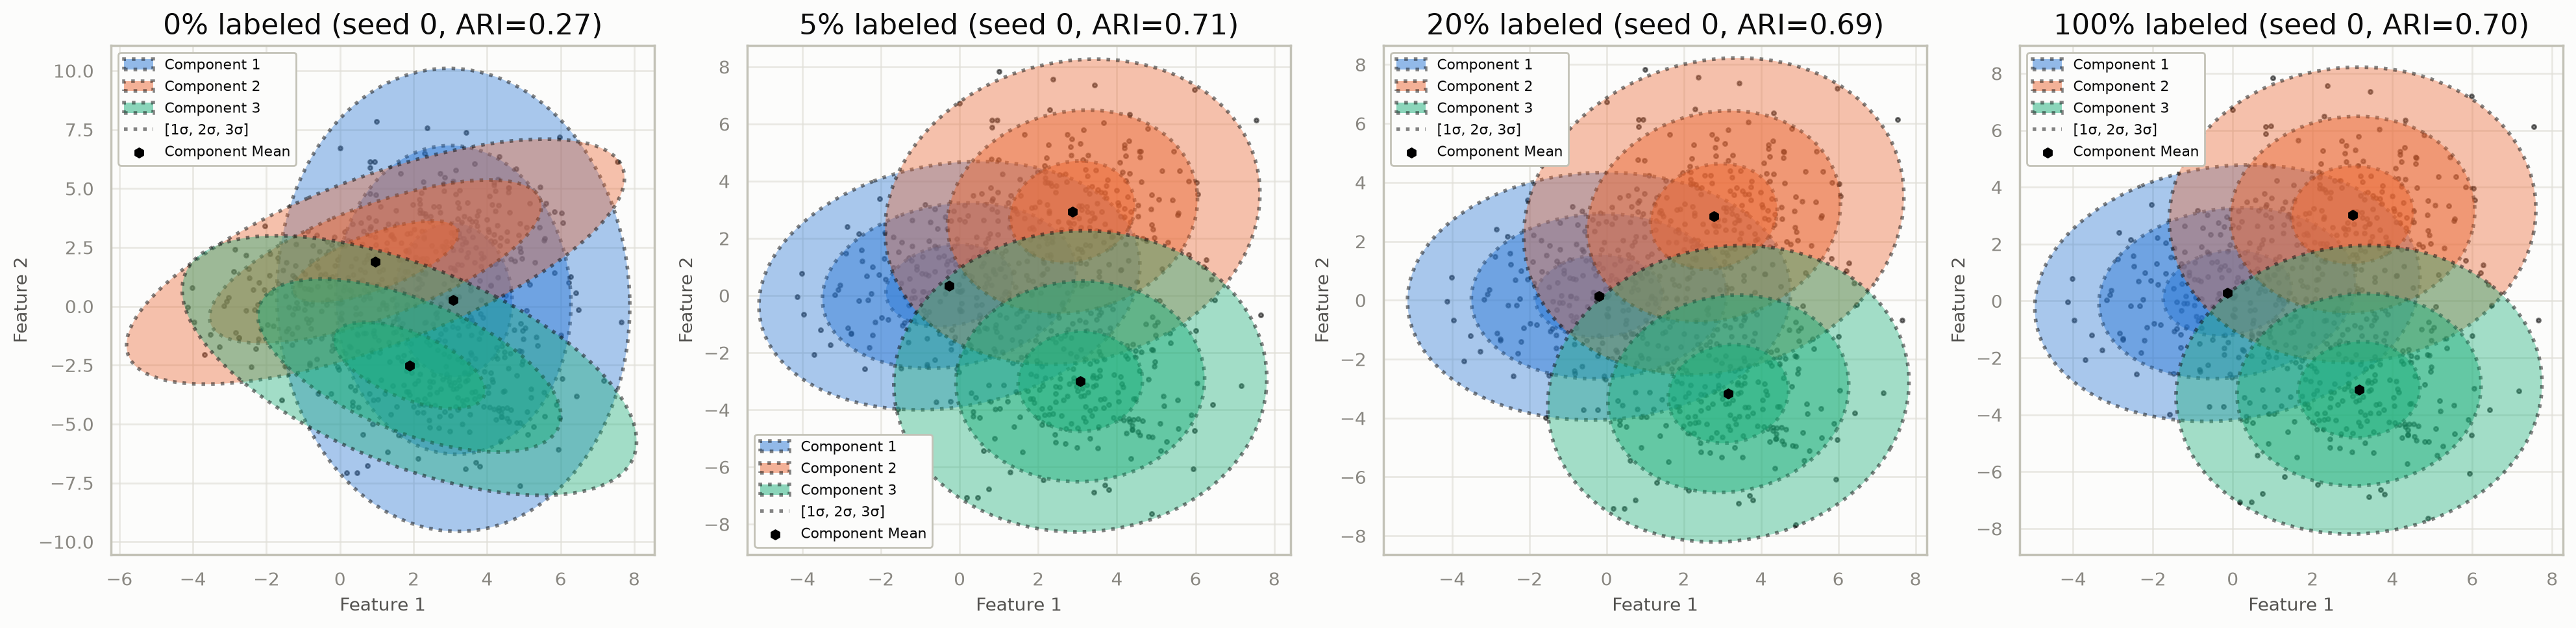

In [ ]:
_fig, _axes = plt.subplots(1, 4, figsize=(20, 5))
for _ax, _frac in zip(_axes, label_fracs):
    _gmm = example_models[_frac]
    _ari = ClusteringMetrics.adjusted_rand_score(true_labels, _gmm.predict(X))
    plot_gmm(X, gmm=_gmm, ax=_ax, title=f'{int(_frac * 100)}% labeled (seed 0, ARI={_ari:.2f})')
plt.tight_layout()
plt.gcf()

Even a handful of labels (5-20%) measurably improves cluster recovery over plain
unsupervised EM on this ambiguous, overlapping data (here, deliberately run from a single
random initialization so unsupervised EM's local-optimum quality varies -- with a strong
initializer like k-means and several restarts, as `GaussianMixture` uses by default, plain
unsupervised EM would already resolve this particular dataset well on its own, and the only
thing labels would add is knowing *which* cluster is which class, which `adjusted_rand_score`
itself can't measure since it's invariant to how clusters are numbered).

## Part 2: positive-unlabeled learning on a "cancer cells vs. everything else" simulation

A `StudentTMixture`-based PU model: a minority "cancer cell" population with heavier-tailed
within-class variation (some genuinely atypical cells), embedded in a larger population of
several other, unlabeled cell types. Only a small fraction of the true positives are
confirmed-labeled; everything else is unlabeled.

In [ ]:
d = 10
_gen = torch.Generator().manual_seed(SEED)
n_positive_true = 150
n_negative_true = 600
pi_true = n_positive_true / (n_positive_true + n_negative_true)
positive_center = torch.full((d,), 3.0)
X_positive = torch.randn(n_positive_true, d, generator=_gen) * 1.0 + positive_center
neg_centers = [torch.full((d,), -3.0), torch.full((d,), -3.0) * torch.tensor([1.0] * 3 + [-1.0] * 7)]
X_negative = torch.cat([torch.randn(n_negative_true // 2, d, generator=_gen) * 1.2 + c for c in neg_centers])
X_pu = torch.cat([X_positive, X_negative])
true_positive = torch.cat([torch.ones(n_positive_true, dtype=torch.bool), torch.zeros(X_negative.shape[0], dtype=torch.bool)])
label_frac = 0.15
gen2 = torch.Generator().manual_seed(SEED + 1)
positive_indices = true_positive.nonzero(as_tuple=True)[0]
n_labeled = int(label_frac * positive_indices.numel())
labeled_idx = positive_indices[torch.randperm(positive_indices.numel(), generator=gen2)[:n_labeled]]
positive_mask = torch.zeros(X_pu.shape[0], dtype=torch.bool)
positive_mask[labeled_idx] = True
print(f'True class prior (fraction positive): {pi_true:.3f}')
print(f'Labeled positives: {positive_mask.sum().item()} / {true_positive.sum().item()} true positives')

True class prior (fraction positive): 0.200
Labeled positives: 22 / 150 true positives


In [ ]:
pu = PositiveUnlabeledMixture(n_components_positive=1, n_components_negative=2, family='student_t', anchor='fixed', random_state=SEED, n_init=min(3, N_INIT), max_iter=200)
pu.fit(X_pu, positive_mask)
pred_positive = pu.predict_positive(X_pu)
tp = (pred_positive & true_positive).sum().item()
fp = (pred_positive & ~true_positive).sum().item()
fn = (~pred_positive & true_positive).sum().item()
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
pi_unlabeled_true = true_positive[~positive_mask].float().mean().item()
print(f'Estimated class_prior_ (fraction of UNLABELED rows that are positive): {pu.class_prior_:.3f}')
print(f'True fraction of unlabeled rows that are positive:                      {pi_unlabeled_true:.3f}')
print(f'F1 of predict_positive on all rows (vs. true positives):                {f1:.3f}')

Estimated class_prior_ (fraction of UNLABELED rows that are positive): 0.073
True fraction of unlabeled rows that are positive:                      0.176
F1 of predict_positive on all rows (vs. true positives):                0.696


### The positive-probability map

Projecting onto the first two dimensions (where the positive/negative separation is
strongest by construction): confirmed-labeled positives are marked with a star, and color
shows `predict_proba_positive` for every row -- the model's estimate of how likely each
*unlabeled* row is to actually be positive.

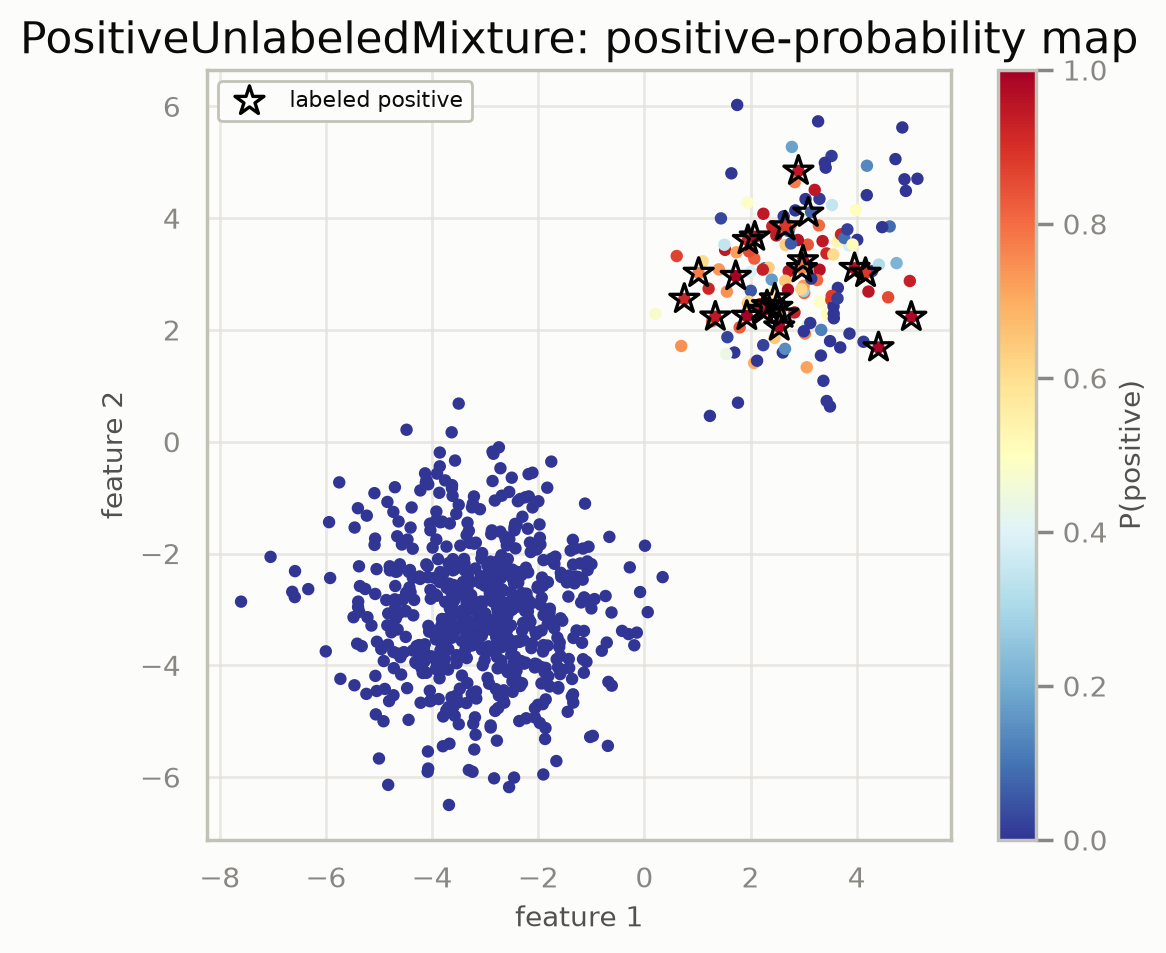

In [ ]:
proba_positive = pu.predict_proba_positive(X_pu)
plt.figure(figsize=(6, 5))
_sc = plt.scatter(X_pu[:, 0], X_pu[:, 1], c=proba_positive, cmap='RdYlBu_r', s=12, vmin=0, vmax=1)
plt.scatter(X_pu[positive_mask, 0], X_pu[positive_mask, 1], marker='*', s=120, facecolors='none', edgecolors='black', linewidths=1.2, label='labeled positive')
plt.colorbar(_sc, label='P(positive)')
plt.legend()
plt.title('PositiveUnlabeledMixture: positive-probability map')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.gcf()

## Summary

- Semi-supervised fitting (`fit(X, labels=...)` with `-1` for unknown) works on every tgmm mixture family, and a modest labeling budget can noticeably improve cluster recovery on ambiguous, overlapping data.
- `PositiveUnlabeledMixture` estimates the class prior (the fraction of *unlabeled* rows that are positive) and a per-row positive probability from only a small labeled positive subset, under the SCAR assumption -- useful whenever confirming a negative is expensive or impossible, but confirming a positive is not.
- `anchor` controls how tightly the positive block stays tied to the labeled positives, which is what keeps the problem identifiable.

**Next:** back to the [tutorial overview](../tutorials/index.md), or the [user guide](../user-guide/semi-supervised-pu.md) for the full parameter reference.